# Recalque de estaca escavada: FOSM e Monte Carlo

Código do TCC - Kaysa Matos da Silva - Engenharia Civil (UESC). Dados do estudo de caso: Saraiva Júnior (2024).

## 1. Parâmetros de entrada

In [ ]:
import os
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.stats import rankdata
from IPython.display import display

warnings.filterwarnings("ignore", category=RuntimeWarning)

# 1.1 Médias (dados da dissertação, Saraiva Júnior, 2024)
MEDIA_E = 12_000.0                    # módulo de deformabilidade do solo (kPa), solo natural de 0 a 6 m
MEDIA_D = 0.25                        # diâmetro da estaca (m)
CARGAS = {"Q1": 131.0, "Q2": 105.0}   # cargas de serviço (kN), com Qu = 210 kN e FS = 1,6 e 2,0

# 1.2 Coeficientes de variação (hipóteses do estudo)
CV = {"E": 0.30,    # módulo do solo (Phoon e Kulhawy, 1999)
      "Q": 0.10,    # carga (JCSS, 2001)
      "D": 0.03}    # diâmetro (JCSS, 2001)

# 1.3 Distribuições (variáveis independentes)
DISTRIBUICAO = {"E": "lognormal", "Q": "lognormal", "D": "normal"}

# 1.4 Recalque admissível e varreduras de sensibilidade
S_ADM = 10.0                                      # caso base (mm)
S_ADM_VARREDURA = [5.0, 7.5, 10.0, 15.0, 25.0]    # mm
CV_E_VARREDURA = [0.10, 0.20, 0.30, 0.40, 0.50, 0.60]

# 1.5 Monte Carlo
N_SIM = 10_000_000          # simulação principal (10^7)
SEMENTE = 42                # semente fixa, para repetir os mesmos resultados

# convergência (seção 10), em lotes para economizar memória
N_CONV = 1_000_000_000      # 10^9; para um teste rápido use 100_000_000
LOTE = 2_000_000
MARCOS = [10**6, 10**7, 10**8, 10**9]    # valores de N mostrados na tabela

# 1.6 Fator de influência de Poulos e Davis (1980): I = I0 * Rk * Rh * Rv * Rb
FATORES = {"I0": 0.075, "Rk": 1.03, "Rh": 0.88, "Rv": 0.92, "Rb": 0.98}
I_FIXO = FATORES["I0"] * FATORES["Rk"] * FATORES["Rh"] * FATORES["Rv"] * FATORES["Rb"]

# Recalques de referência (só para comparar)
S_AUTOR = {"Q1": 4.21, "Q2": 3.37}   # calculados na dissertação, com Rk = 1,62 (mm)
S_PCE = {"Q1": 3.2, "Q2": 2.1}       # medidos na prova de carga estática (mm)

# 1.7 Pasta de saída
PASTA = "resultados_pf_recalque"
os.makedirs(PASTA, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.grid": True, "grid.alpha": 0.3})

def salvar(fig, nome):
    fig.savefig(f"{PASTA}/{nome}", dpi=300, bbox_inches="tight")

resumo = pd.DataFrame([
    ["E (módulo do solo)", MEDIA_E, "kPa", CV["E"], DISTRIBUICAO["E"]],
    ["Q (carga)", "131 (Q1) e 105 (Q2)", "kN", CV["Q"], DISTRIBUICAO["Q"]],
    ["D (diâmetro)", MEDIA_D, "m", CV["D"], DISTRIBUICAO["D"]],
], columns=["Variável", "Média", "Unidade", "CV", "Distribuição"])
display(resumo)
print(f"Recalque admissível: {S_ADM} mm | Monte Carlo: N = {N_SIM:,} | semente = {SEMENTE}")

,Variável,Média,Unidade,CV,Distribuição
0,E (módulo do solo),12000.0,kPa,0.30,lognormal
1,Q (carga),131 (Q1) e 105 (Q2),kN,0.10,lognormal
2,D (diâmetro),0.25,m,0.03,normal


Recalque admissível: 10.0 mm | Monte Carlo: N = 10,000,000 | semente = 42


## 2. Modelo determinístico (Poulos e Davis, 1980)

In [ ]:
def recalque_mm(Q, E, D, I):
    # Q em kN, E em kPa e D em m dão s em m; o fator 1000 passa para mm
    return 1000.0 * I * Q / (E * D)

print("Fatores de Poulos e Davis:", FATORES)
print(f"I = {I_FIXO:.5f}")

linhas = []
for nome, Q in CARGAS.items():
    s_mod = recalque_mm(Q, MEDIA_E, MEDIA_D, I_FIXO)
    linhas.append([nome, Q, S_PCE[nome], S_AUTOR[nome], s_mod,
                   S_AUTOR[nome] / S_PCE[nome], s_mod / S_PCE[nome]])
tab_det = pd.DataFrame(linhas, columns=["Carga", "Q (kN)", "s prova de carga (mm)", "s dissertação (mm)",
                                        "s corrigido (mm)", "s dissertação / s medido", "s corrigido / s medido"])
display(tab_det.round(3))
tab_det.to_csv(f"{PASTA}/tabela_determinista.csv", index=False)

Fatores de Poulos e Davis: {'I0': 0.075, 'Rk': 1.03, 'Rh': 0.88, 'Rv': 0.92, 'Rb': 0.98}
I = 0.06129


,Carga,Q (kN),s prova de carga (mm),s dissertação (mm),s corrigido (mm),s dissertação / s medido,s corrigido / s medido
0,Q1,131.0,3.2,4.21,2.676,1.316,0.836
1,Q2,105.0,2.1,3.37,2.145,1.605,1.022


## 3. Variáveis aleatórias

In [ ]:
def params_lognormal(media, cv):
    # devolve (média, desvio-padrão) do logaritmo da variável
    sigma2 = np.log(1.0 + cv**2)
    return np.log(media) - 0.5 * sigma2, np.sqrt(sigma2)

def amostrar(rng, n, media, cv, dist):
    if dist == "lognormal":
        mu, sg = params_lognormal(media, cv)
        return rng.lognormal(mean=mu, sigma=sg, size=n)
    if dist == "normal":
        return rng.normal(loc=media, scale=cv * media, size=n)
    raise ValueError("Distribuição desconhecida: " + dist)

# teste: média e CV das amostras
rng_teste = np.random.default_rng(0)
linhas = []
for var, media in [("E", MEDIA_E), ("Q", CARGAS["Q1"]), ("D", MEDIA_D)]:
    x = amostrar(rng_teste, 500_000, media, CV[var], DISTRIBUICAO[var])
    linhas.append([var, DISTRIBUICAO[var], media, x.mean(), CV[var], x.std(ddof=1) / x.mean()])
display(pd.DataFrame(linhas, columns=["Variável", "Distribuição", "Média de entrada", "Média amostral",
                                      "CV de entrada", "CV amostral"]).round(4))

,Variável,Distribuição,Média de entrada,Média amostral,CV de entrada,CV amostral
0,E,lognormal,12000.00,12007.1894,0.30,0.3003
1,Q,lognormal,131.00,131.0038,0.10,0.1000
2,D,normal,0.25,0.2500,0.03,0.0299


## 4. Monte Carlo

In [ ]:
def wilson(k, n, z=1.96):
    # intervalo de confiança de Wilson para a proporção k/n (aceita números ou vetores)
    p = k / n
    centro = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    meia = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return np.maximum(centro - meia, 0.0), centro + meia

def simular(n, cv_E, rng):
    # sorteia E, D e Q (uma amostra de Q para cada carga) e calcula o recalque em mm
    E = amostrar(rng, n, MEDIA_E, cv_E, DISTRIBUICAO["E"])
    D = amostrar(rng, n, MEDIA_D, CV["D"], DISTRIBUICAO["D"])
    saida = {}
    for nome, Qm in CARGAS.items():
        Q = amostrar(rng, n, Qm, CV["Q"], DISTRIBUICAO["Q"])
        saida[nome] = {"E": E, "Q": Q, "D": D, "s": recalque_mm(Q, E, D, I_FIXO)}
    return saida

def pf_mc(s, s_adm):
    n = len(s)
    k = int(np.count_nonzero(s > s_adm))
    p = k / n
    se = np.sqrt(p * (1 - p) / n)
    inf, sup = wilson(k, n)
    return {"k": k, "pf": p, "se": se, "ic_inf": inf, "ic_sup": sup}

def fmt_pf(x):
    return "0" if x == 0 else f"{x:.2e}"

# Simulação principal (caso central)
rng = np.random.default_rng(SEMENTE)
sim = simular(N_SIM, CV["E"], rng)

linhas = []
for nome in CARGAS:
    s = sim[nome]["s"]
    p5, p50, p95 = np.percentile(s, [5, 50, 95])
    pf = pf_mc(s, S_ADM)
    linhas.append([nome, s.mean(), s.std(ddof=1), s.std(ddof=1) / s.mean(), p5, p50, p95,
                   pf["k"], fmt_pf(pf["pf"]), fmt_pf(pf["se"]),
                   f"[{fmt_pf(pf['ic_inf'])} ; {fmt_pf(pf['ic_sup'])}]"])
tab_mc = pd.DataFrame(linhas, columns=["Carga", "média s (mm)", "desvio s (mm)", "CV s", "P5 (mm)", "P50 (mm)",
                                       "P95 (mm)", "Nº excedências", f"Pf (s>{S_ADM:g} mm)", "erro-padrão", "IC 95%"])
display(tab_mc.round(4))
tab_mc.to_csv(f"{PASTA}/tabela_monte_carlo.csv", index=False)

,Carga,média s (mm),desvio s (mm),CV s,P5 (mm),P50 (mm),P95 (mm),Nº excedências,Pf (s>10 mm),erro-padrão,IC 95%
0,Q1,2.9199,0.9321,0.3192,1.6666,2.7816,4.6422,206,2.06e-05,1.44e-06,[1.80e-05 ; 2.36e-05]
1,Q2,2.3403,0.7470,0.3192,1.3359,2.2295,3.7211,8,8.00e-07,2.83e-07,[4.05e-07 ; 1.58e-06]


## 5. FOSM

In [ ]:
def fosm(Q_med, cv_E, cv_Q, cv_D, s_adm):
    s0 = recalque_mm(Q_med, MEDIA_E, MEDIA_D, I_FIXO)    # recalque calculado com as médias
    cvs = {"E": cv_E, "Q": cv_Q, "D": cv_D}

    # Formulação A: cada termo (ds/dx * sigma)^2 vale (s0 * cv)^2
    var_A = {k: (s0 * c) ** 2 for k, c in cvs.items()}
    sd_A = np.sqrt(sum(var_A.values()))
    beta_A = (s_adm - s0) / sd_A
    A = {"media": s0, "desvio": sd_A, "cv": sd_A / s0, "beta": beta_A, "pf": stats.norm.sf(beta_A),
         "contrib": {k: v / sum(var_A.values()) for k, v in var_A.items()}}

    # Formulação B: ln s = ln(1000*I) + ln Q - ln E - ln D
    pE = params_lognormal(MEDIA_E, cv_E)
    pQ = params_lognormal(Q_med, cv_Q)
    pD = params_lognormal(MEDIA_D, cv_D)
    mu_ln = np.log(1000.0 * I_FIXO) + pQ[0] - pE[0] - pD[0]
    var_ln = {"E": pE[1] ** 2, "Q": pQ[1] ** 2, "D": pD[1] ** 2}
    sd_ln = np.sqrt(sum(var_ln.values()))
    beta_B = (np.log(s_adm) - mu_ln) / sd_ln
    media_B = np.exp(mu_ln + sd_ln**2 / 2)
    desvio_B = media_B * np.sqrt(np.exp(sd_ln**2) - 1)
    B = {"media": media_B, "desvio": desvio_B, "cv": desvio_B / media_B, "beta": beta_B,
         "pf": stats.norm.sf(beta_B), "mu_ln": mu_ln, "sd_ln": sd_ln,
         "contrib": {k: v / sum(var_ln.values()) for k, v in var_ln.items()}}
    return {"A": A, "B": B}

# teste da derivada em relação a E
Qt = CARGAS["Q1"]
s_ref = recalque_mm(Qt, MEDIA_E, MEDIA_D, I_FIXO)
h = 1e-4
dsdE = (recalque_mm(Qt, MEDIA_E * (1 + h), MEDIA_D, I_FIXO)
        - recalque_mm(Qt, MEDIA_E * (1 - h), MEDIA_D, I_FIXO)) / (2 * h * MEDIA_E)
assert abs(dsdE - (-s_ref / MEDIA_E)) < 1e-5 * abs(s_ref / MEDIA_E), "derivada analítica diferente da numérica"
print("derivada ok")

ROTULO = {"A": "FOSM-A (s linear, β normal)", "B": "FOSM-B (ln s, lognormal)"}

linhas = []
for nome, Qm in CARGAS.items():
    f = fosm(Qm, CV["E"], CV["Q"], CV["D"], S_ADM)
    for chave in ("A", "B"):
        r = f[chave]
        linhas.append([nome, ROTULO[chave], r["media"], r["desvio"], r["cv"], r["beta"], fmt_pf(r["pf"])])
tab_fosm = pd.DataFrame(linhas, columns=["Carga", "Formulação", "média s (mm)", "desvio s (mm)", "CV s", "β",
                                         f"Pf (s>{S_ADM:g} mm)"])
display(tab_fosm.round(4))
tab_fosm.to_csv(f"{PASTA}/tabela_fosm.csv", index=False)

derivada ok


,Carga,Formulação,média s (mm),desvio s (mm),CV s,β,Pf (s>10 mm)
0,Q1,"FOSM-A (s linear, β normal)",2.6764,0.8501,0.3176,8.6146,3.51e-18
1,Q1,"FOSM-B (ln s, lognormal)",2.9199,0.9320,0.3192,4.1078,2.00e-05
2,Q2,"FOSM-A (s linear, β normal)",2.1452,0.6814,0.3176,11.5273,4.81e-31
3,Q2,"FOSM-B (ln s, lognormal)",2.3403,0.7470,0.3192,4.8181,7.25e-07


## 6. Comparação entre FOSM e Monte Carlo

In [ ]:
linhas = []
for nome, Qm in CARGAS.items():
    s = sim[nome]["s"]
    pf = pf_mc(s, S_ADM)
    beta_mc = -stats.norm.ppf(pf["pf"]) if pf["pf"] > 0 else np.nan
    linhas.append([nome, "Monte Carlo", s.mean(), s.std(ddof=1), s.std(ddof=1) / s.mean(), beta_mc, pf["pf"]])
    f = fosm(Qm, CV["E"], CV["Q"], CV["D"], S_ADM)
    for chave in ("A", "B"):
        r = f[chave]
        linhas.append([nome, ROTULO[chave], r["media"], r["desvio"], r["cv"], r["beta"], r["pf"]])

tab_comp = pd.DataFrame(linhas, columns=["Carga", "Método", "μ_s (mm)", "σ_s (mm)", "CV_s", "β", "Pf"])
tab_comp.to_csv(f"{PASTA}/tabela_comparacao.csv", index=False)
exibe = tab_comp.copy()
exibe["Pf"] = exibe["Pf"].map(fmt_pf)
display(exibe.round(4))

# razão entre as Pf
for nome in CARGAS:
    sub = tab_comp[tab_comp["Carga"] == nome].set_index("Método")["Pf"]
    if sub["Monte Carlo"] > 0:
        print(f"{nome}: Pf(FOSM-A)/Pf(MC) = {sub[ROTULO['A']] / sub['Monte Carlo']:.3g} | "
              f"Pf(FOSM-B)/Pf(MC) = {sub[ROTULO['B']] / sub['Monte Carlo']:.3g}")

,Carga,Método,μ_s (mm),σ_s (mm),CV_s,β,Pf
0,Q1,Monte Carlo,2.9199,0.9321,0.3192,4.1006,2.06e-05
1,Q1,"FOSM-A (s linear, β normal)",2.6764,0.8501,0.3176,8.6146,3.51e-18
2,Q1,"FOSM-B (ln s, lognormal)",2.9199,0.9320,0.3192,4.1078,2.00e-05
3,Q2,Monte Carlo,2.3403,0.7470,0.3192,4.7983,8.00e-07
4,Q2,"FOSM-A (s linear, β normal)",2.1452,0.6814,0.3176,11.5273,4.81e-31
5,Q2,"FOSM-B (ln s, lognormal)",2.3403,0.7470,0.3192,4.8181,7.25e-07


Q1: Pf(FOSM-A)/Pf(MC) = 1.7e-13 | Pf(FOSM-B)/Pf(MC) = 0.969
Q2: Pf(FOSM-A)/Pf(MC) = 6.01e-25 | Pf(FOSM-B)/Pf(MC) = 0.906


### 6.1 Distribuição do recalque

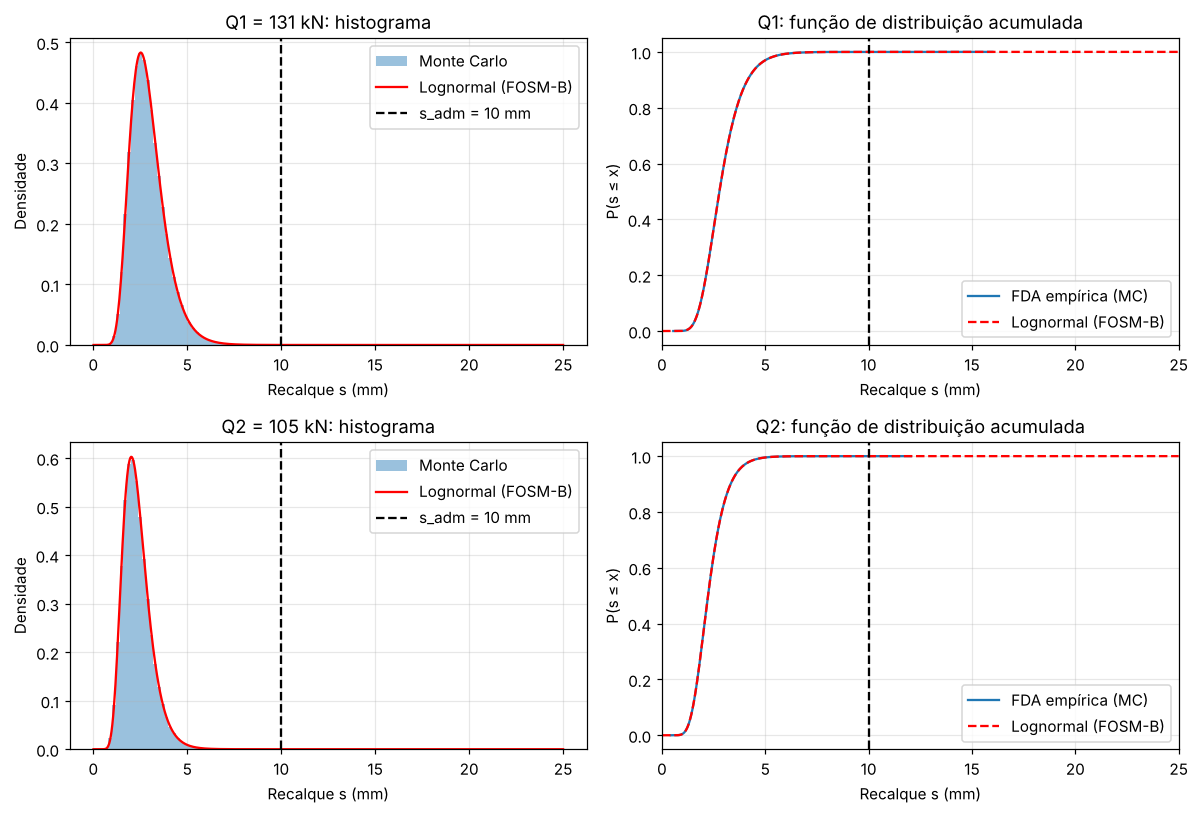

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7.5))
sorted_s = {}
xs = np.linspace(0.01, 25, 600)
for i, (nome, Qm) in enumerate(CARGAS.items()):
    s = sim[nome]["s"]
    sorted_s[nome] = np.sort(s)
    fB = fosm(Qm, CV["E"], CV["Q"], CV["D"], S_ADM)["B"]
    lognorm = stats.lognorm(s=fB["sd_ln"], scale=np.exp(fB["mu_ln"]))

    ax = axes[i, 0]
    cont, bordas = np.histogram(s, bins=125, range=(0, 25))
    dens = cont / (len(s) * (bordas[1] - bordas[0]))
    ax.stairs(dens, bordas, fill=True, alpha=0.45, label="Monte Carlo")
    ax.plot(xs, lognorm.pdf(xs), "r-", lw=1.5, label="Lognormal (FOSM-B)")
    ax.axvline(S_ADM, color="k", ls="--", label=f"s_adm = {S_ADM:g} mm")
    ax.set_xlabel("Recalque s (mm)")
    ax.set_ylabel("Densidade")
    ax.set_title(f"{nome} = {Qm:g} kN: histograma")
    ax.legend()

    ax = axes[i, 1]
    idx = np.linspace(0, len(s) - 1, 3000).astype(int)
    ax.plot(sorted_s[nome][idx], (idx + 1) / len(s), label="FDA empírica (MC)")
    ax.plot(xs, lognorm.cdf(xs), "r--", label="Lognormal (FOSM-B)")
    ax.axvline(S_ADM, color="k", ls="--")
    ax.set_xlim(0, 25)
    ax.set_xlabel("Recalque s (mm)")
    ax.set_ylabel("P(s ≤ x)")
    ax.set_title(f"{nome}: função de distribuição acumulada")
    ax.legend()
fig.tight_layout()
salvar(fig, "fig1_distribuicao_recalque.png")
plt.show()

### 6.2 Convergência de Pf até 10⁷

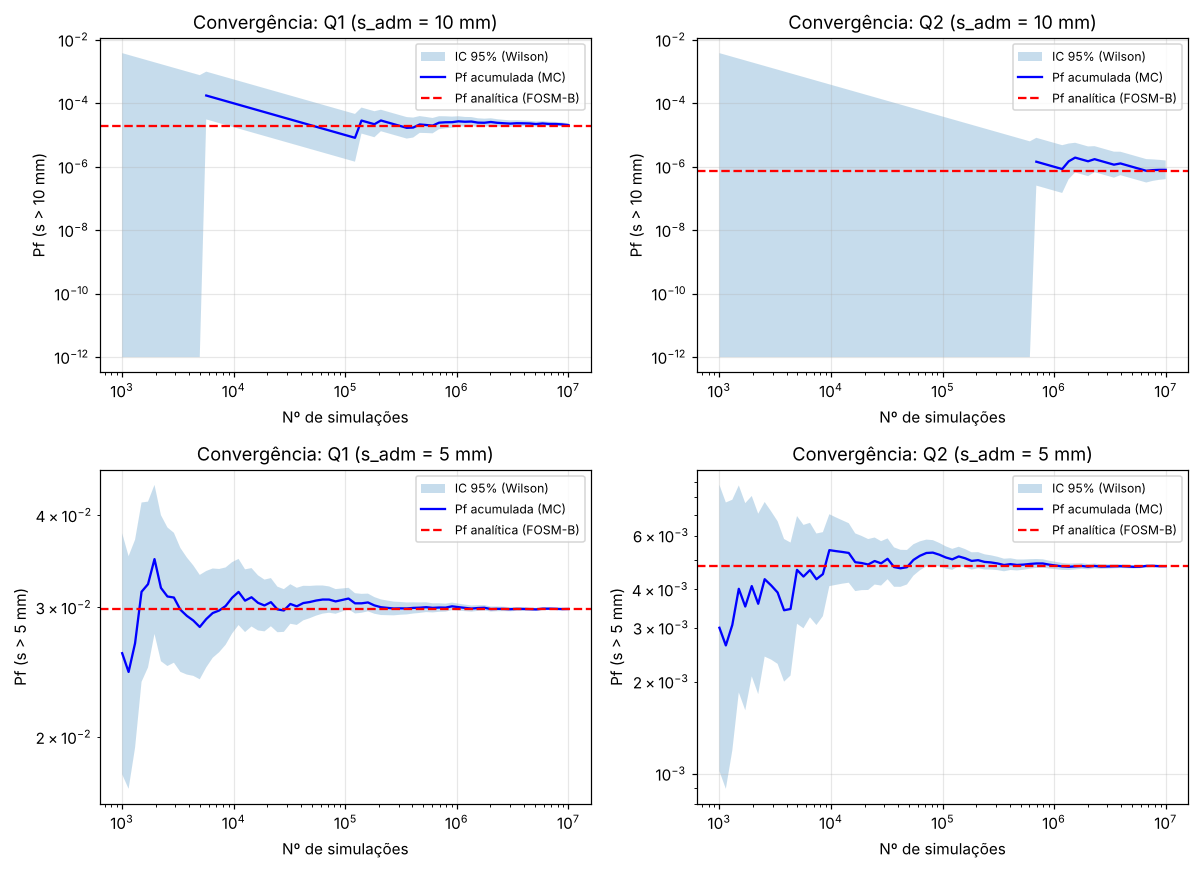

In [ ]:
LIMITES_CONV = [S_ADM, 5.0]
ns = np.unique(np.logspace(3, np.log10(N_SIM), 70).astype(int))

fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for i, lim in enumerate(LIMITES_CONV):
    for ax, (nome, Qm) in zip(axes[i], CARGAS.items()):
        k = np.cumsum(sim[nome]["s"] > lim)[ns - 1].astype(float)    # excedências acumuladas
        p = k / ns
        inf, sup = wilson(k, ns)
        ax.fill_between(ns, np.maximum(inf, 1e-12), sup, alpha=0.25, label="IC 95% (Wilson)")
        ax.plot(ns, np.where(p > 0, p, np.nan), "b-", label="Pf acumulada (MC)")
        ax.axhline(fosm(Qm, CV["E"], CV["Q"], CV["D"], lim)["B"]["pf"], color="r", ls="--",
                   label="Pf analítica (FOSM-B)")
        ax.set_xscale("log")
        ax.set_yscale("log")
        ax.set_xlabel("Nº de simulações")
        ax.set_ylabel(f"Pf (s > {lim:g} mm)")
        ax.set_title(f"Convergência: {nome} (s_adm = {lim:g} mm)")
        ax.legend(fontsize=8)
fig.tight_layout()
salvar(fig, "fig2_convergencia_pf_1e7.png")
plt.show()

## 7. Variáveis de maior influência

,Carga,Variável,FOSM-A: % da variância,FOSM-B: % da variância (ln s),Spearman ρ (MC),ρ² normalizado (%)
0,Q1,E,89.197,88.818,-0.937,89.497
1,Q1,Q,9.911,10.255,0.308,9.642
2,Q1,D,0.892,0.927,-0.092,0.861
3,Q2,E,89.197,88.818,-0.937,89.508
4,Q2,Q,9.911,10.255,0.307,9.627
5,Q2,D,0.892,0.927,-0.092,0.865


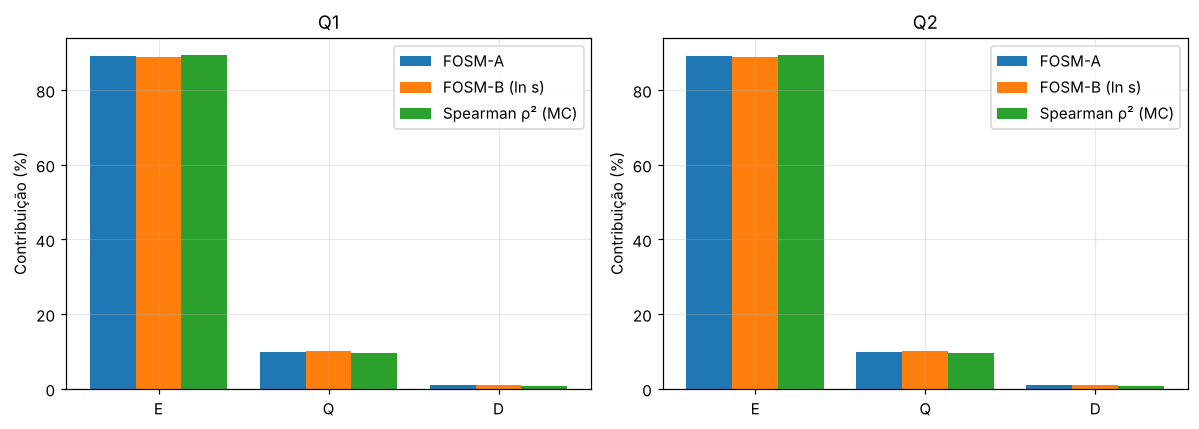

In [ ]:
def spearman(x, y):
    return np.corrcoef(rankdata(x), rankdata(y))[0, 1]

linhas = []
for nome, Qm in CARGAS.items():
    f = fosm(Qm, CV["E"], CV["Q"], CV["D"], S_ADM)
    rho = {v: spearman(sim[nome][v], sim[nome]["s"]) for v in ["E", "Q", "D"]}
    soma = sum(r**2 for r in rho.values())
    for v in ["E", "Q", "D"]:
        linhas.append([nome, v, 100 * f["A"]["contrib"][v], 100 * f["B"]["contrib"][v],
                       rho[v], 100 * rho[v]**2 / soma])
tab_inf = pd.DataFrame(linhas, columns=["Carga", "Variável", "FOSM-A: % da variância",
                                        "FOSM-B: % da variância (ln s)", "Spearman ρ (MC)", "ρ² normalizado (%)"])
display(tab_inf.round(3))
tab_inf.to_csv(f"{PASTA}/tabela_influencia.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
largura = 0.27
x = np.arange(3)
for ax, nome in zip(axes, CARGAS):
    sub = tab_inf[tab_inf["Carga"] == nome]
    ax.bar(x - largura, sub["FOSM-A: % da variância"], largura, label="FOSM-A")
    ax.bar(x, sub["FOSM-B: % da variância (ln s)"], largura, label="FOSM-B (ln s)")
    ax.bar(x + largura, sub["ρ² normalizado (%)"], largura, label="Spearman ρ² (MC)")
    ax.set_xticks(x)
    ax.set_xticklabels(["E", "Q", "D"])
    ax.set_ylabel("Contribuição (%)")
    ax.set_title(nome)
    ax.legend()
fig.tight_layout()
salvar(fig, "fig3_influencia_parametros.png")
plt.show()

## 8. Sensibilidade ao CV do módulo

,Carga,CV_E,Nº excedências,Pf_MC,IC_inf,IC_sup,Pf_FOSM_A,Pf_FOSM_B,%var_E (FOSM-A)
0,Q1,0.1,0,0,0,3.84e-07,3.34e-80,3.23e-20,47.847
1,Q2,0.1,0,0,0,3.84e-07,7.86e-142,7.00e-27,47.847
2,Q1,0.2,0,0,0,3.84e-07,3.71e-34,2.89e-09,78.585
3,Q2,0.2,0,0,0,3.84e-07,1.55e-59,4.81e-12,78.585
4,Q1,0.3,213,2.13e-05,1.86e-05,2.44e-05,3.51e-18,2.00e-05,89.197
5,Q2,0.3,3,3.00e-07,1.02e-07,8.82e-07,4.81e-31,7.25e-07,89.197
6,Q1,0.4,8740,8.74e-04,8.56e-04,8.93e-04,1.80e-11,8.79e-04,93.622
7,Q2,0.4,1168,1.17e-04,1.10e-04,1.24e-04,4.10e-19,1.15e-04,93.622
8,Q1,0.5,61620,6.16e-03,6.11e-03,6.21e-03,4.22e-08,6.15e-03,95.822
9,Q2,0.5,15311,1.53e-03,1.51e-03,1.56e-03,3.79e-13,1.53e-03,95.822


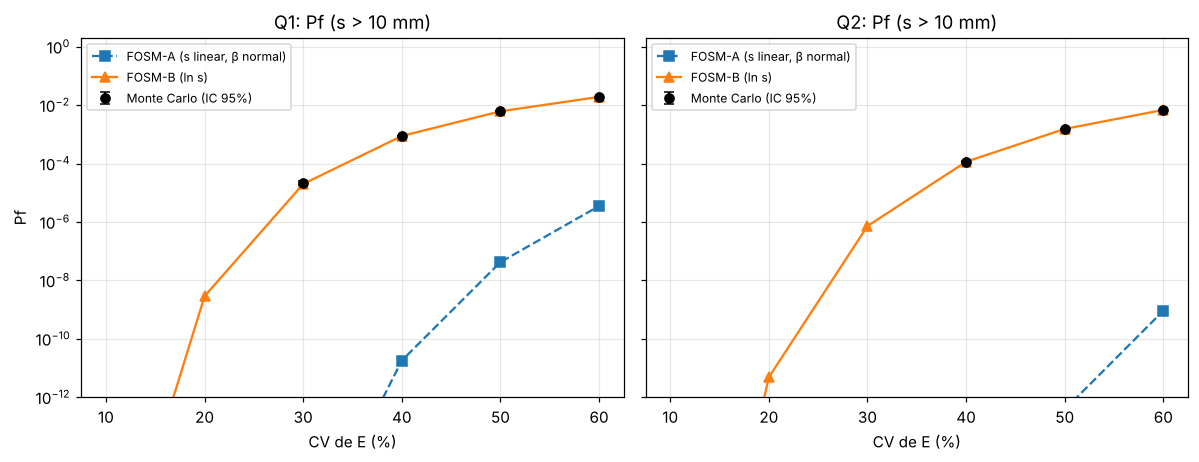

In [ ]:
rng_v = np.random.default_rng(SEMENTE + 1)
reg = []
for cvE in CV_E_VARREDURA:
    simv = simular(N_SIM, cvE, rng_v)
    for nome, Qm in CARGAS.items():
        pf = pf_mc(simv[nome]["s"], S_ADM)
        f = fosm(Qm, cvE, CV["Q"], CV["D"], S_ADM)
        reg.append({"Carga": nome, "CV_E": cvE, "Nº excedências": pf["k"], "Pf_MC": pf["pf"],
                    "IC_inf": pf["ic_inf"], "IC_sup": pf["ic_sup"],
                    "Pf_FOSM_A": f["A"]["pf"], "Pf_FOSM_B": f["B"]["pf"],
                    "%var_E (FOSM-A)": 100 * f["A"]["contrib"]["E"]})
    del simv

tab_cv = pd.DataFrame(reg)
tab_cv.to_csv(f"{PASTA}/tabela_sensibilidade_cv_E.csv", index=False)
exibe = tab_cv.copy()
for c in ["Pf_MC", "IC_inf", "IC_sup", "Pf_FOSM_A", "Pf_FOSM_B"]:
    exibe[c] = exibe[c].map(fmt_pf)
display(exibe.round(3))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.3), sharey=True)
for ax, nome in zip(axes, CARGAS):
    sub = tab_cv[tab_cv["Carga"] == nome]
    ok = sub["Nº excedências"] >= 10
    ax.errorbar(sub.loc[ok, "CV_E"] * 100, sub.loc[ok, "Pf_MC"],
                yerr=[sub.loc[ok, "Pf_MC"] - sub.loc[ok, "IC_inf"], sub.loc[ok, "IC_sup"] - sub.loc[ok, "Pf_MC"]],
                fmt="ko", capsize=3, label="Monte Carlo (IC 95%)")
    ax.plot(sub["CV_E"] * 100, sub["Pf_FOSM_A"], "s--", label="FOSM-A (s linear, β normal)")
    ax.plot(sub["CV_E"] * 100, sub["Pf_FOSM_B"], "^-", label="FOSM-B (ln s)")
    ax.set_yscale("log")
    ax.set_ylim(1e-12, 2)    # valores abaixo de 1e-12 saem do gráfico, mas estão na tabela
    ax.set_xlabel("CV de E (%)")
    ax.set_title(f"{nome}: Pf (s > {S_ADM:g} mm)")
    ax.legend(fontsize=8)
axes[0].set_ylabel("Pf")
fig.tight_layout()
salvar(fig, "fig4_sensibilidade_cv_E.png")
plt.show()

## 9. Sensibilidade ao recalque admissível

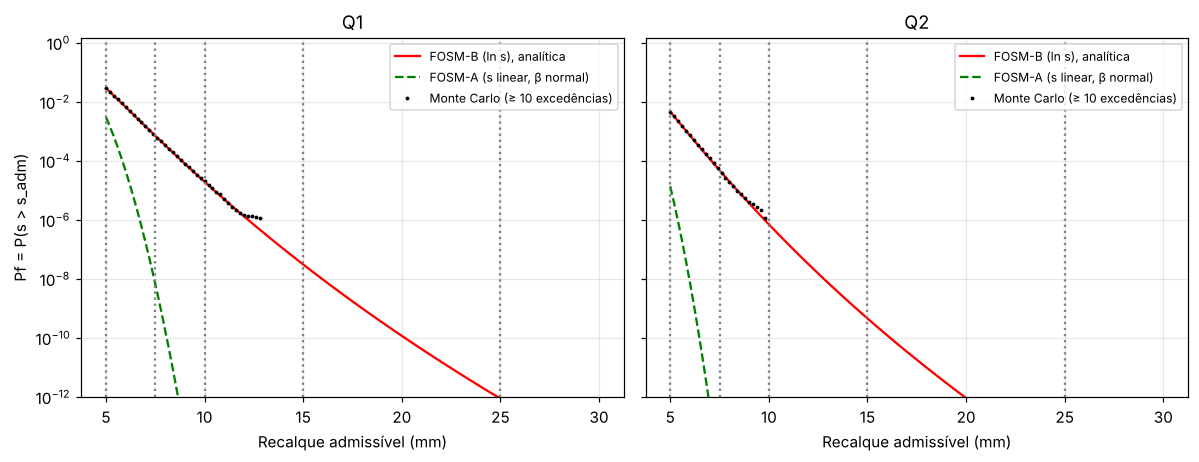

,Carga,s_adm (mm),Nº excedências (MC),Pf_MC,Pf_FOSM_A,Pf_FOSM_B,β_FOSM_B
0,Q1,5.0,298527,2.99e-02,3.14e-03,2.99e-02,1.883
1,Q1,7.5,7340,7.34e-04,6.98e-09,7.26e-04,3.184
2,Q1,10.0,206,2.06e-05,3.51e-18,2.00e-05,4.108
3,Q1,15.0,1,1.00e-07,6.42e-48,3.16e-08,5.410
4,Q1,25.0,0,0,2.84e-152,8.98e-13,7.049
5,Q2,5.0,47662,4.77e-03,1.40e-05,4.76e-03,2.593
6,Q2,7.5,483,4.83e-05,1.94e-15,4.92e-05,3.895
7,Q2,10.0,8,8.00e-07,4.81e-31,7.25e-07,4.818
8,Q2,15.0,0,0,1.11e-79,4.69e-10,6.120
9,Q2,25.0,0,0,6.20e-247,4.26e-15,7.760


In [ ]:
adm = np.linspace(5, 30, 126)
reg = []

fig, axes = plt.subplots(1, 2, figsize=(11, 4.3), sharey=True)
for ax, (nome, Qm) in zip(axes, CARGAS.items()):
    ss = sorted_s[nome]
    exced = len(ss) - np.searchsorted(ss, adm, side="right")
    pf_emp = exced / len(ss)
    pfA = [fosm(Qm, CV["E"], CV["Q"], CV["D"], a)["A"]["pf"] for a in adm]
    pfB = [fosm(Qm, CV["E"], CV["Q"], CV["D"], a)["B"]["pf"] for a in adm]
    ax.plot(adm, pfB, "r-", label="FOSM-B (ln s), analítica")
    ax.plot(adm, pfA, "g--", label="FOSM-A (s linear, β normal)")
    ok = exced >= 10
    ax.plot(adm[ok], pf_emp[ok], "k.", ms=3, label="Monte Carlo (≥ 10 excedências)")
    for a in S_ADM_VARREDURA:
        ax.axvline(a, color="gray", ls=":")
        pf = pf_mc(ss, a)
        f = fosm(Qm, CV["E"], CV["Q"], CV["D"], a)
        reg.append({"Carga": nome, "s_adm (mm)": a, "Nº excedências (MC)": pf["k"], "Pf_MC": pf["pf"],
                    "Pf_FOSM_A": f["A"]["pf"], "Pf_FOSM_B": f["B"]["pf"], "β_FOSM_B": f["B"]["beta"]})
    ax.set_yscale("log")
    ax.set_ylim(1e-12, 1.5)
    ax.set_xlabel("Recalque admissível (mm)")
    ax.set_title(nome)
    ax.legend(fontsize=8)
axes[0].set_ylabel("Pf = P(s > s_adm)")
fig.tight_layout()
salvar(fig, "fig5_sensibilidade_s_adm.png")
plt.show()

tab_adm = pd.DataFrame(reg)
tab_adm.to_csv(f"{PASTA}/tabela_sensibilidade_s_adm.csv", index=False)
exibe = tab_adm.copy()
for c in ["Pf_MC", "Pf_FOSM_A", "Pf_FOSM_B"]:
    exibe[c] = exibe[c].map(fmt_pf)
display(exibe.round(3))

## 10. Convergência do Monte Carlo até 10⁹

In [ ]:
t0 = time.time()
rng_c = np.random.default_rng(SEMENTE + 7)
n_lotes = N_CONV // LOTE
cum = {nome: np.zeros(n_lotes + 1, dtype=np.int64) for nome in CARGAS}    # excedências acumuladas ao fim de cada lote
ini = {nome: None for nome in CARGAS}                                       # excedências acumuladas dentro do 1º lote

for j in range(n_lotes):
    sj = simular(LOTE, CV["E"], rng_c)
    for nome in CARGAS:
        exc = sj[nome]["s"] > S_ADM
        if j == 0:
            ini[nome] = np.cumsum(exc)
        cum[nome][j + 1] = cum[nome][j] + int(exc.sum())
    del sj
print(f"Convergência: N = {N_CONV:,} em {time.time() - t0:.0f} s")

def exced_ate(nome, n):
    # número de excedências nas primeiras n simulações
    if n <= LOTE:
        return int(ini[nome][n - 1])
    return int(cum[nome][n // LOTE])

linhas = []
for nome, Qm in CARGAS.items():
    pfB = fosm(Qm, CV["E"], CV["Q"], CV["D"], S_ADM)["B"]["pf"]
    for n in [m for m in MARCOS if m <= N_CONV]:
        k = exced_ate(nome, n)
        lo, hi = wilson(k, n)
        p = k / n
        linhas.append([nome, n, k, p, (hi - lo) / 2 / p if k > 0 else np.nan, lo, hi, pfB])
tab_conv = pd.DataFrame(linhas, columns=["Carga", "N", "Nº excedências", "Pf_MC", "semi-amplitude do IC / Pf",
                                         "IC_inf", "IC_sup", "Pf_FOSM_B"])
tab_conv.to_csv(f"{PASTA}/tabela_convergencia_longa.csv", index=False)
exibe = tab_conv.copy()
for c in ["Pf_MC", "IC_inf", "IC_sup", "Pf_FOSM_B"]:
    exibe[c] = exibe[c].map(fmt_pf)
display(exibe)

Convergência: N = 1,000,000,000 em 96 s


,Carga,N,Nº excedências,Pf_MC,semi-amplitude do IC / Pf,IC_inf,IC_sup,Pf_FOSM_B
0,Q1,1000000,10,1.00e-05,0.648882,5.43e-06,1.84e-05,2.00e-05
1,Q1,10000000,186,1.86e-05,0.144083,1.61e-05,2.15e-05,2.00e-05
2,Q1,100000000,1962,1.96e-05,0.044260,1.88e-05,2.05e-05,2.00e-05
3,Q1,1000000000,19809,1.98e-05,0.013926,1.95e-05,2.01e-05,2.00e-05
4,Q2,1000000,1,1.00e-06,2.744269,1.77e-07,5.67e-06,7.25e-07
5,Q2,10000000,9,9.00e-07,0.687308,4.74e-07,1.71e-06,7.25e-07
6,Q2,100000000,65,6.50e-07,0.244897,5.10e-07,8.28e-07,7.25e-07
7,Q2,1000000000,692,6.92e-07,0.074560,6.42e-07,7.46e-07,7.25e-07


### 10.1 Figura de convergência

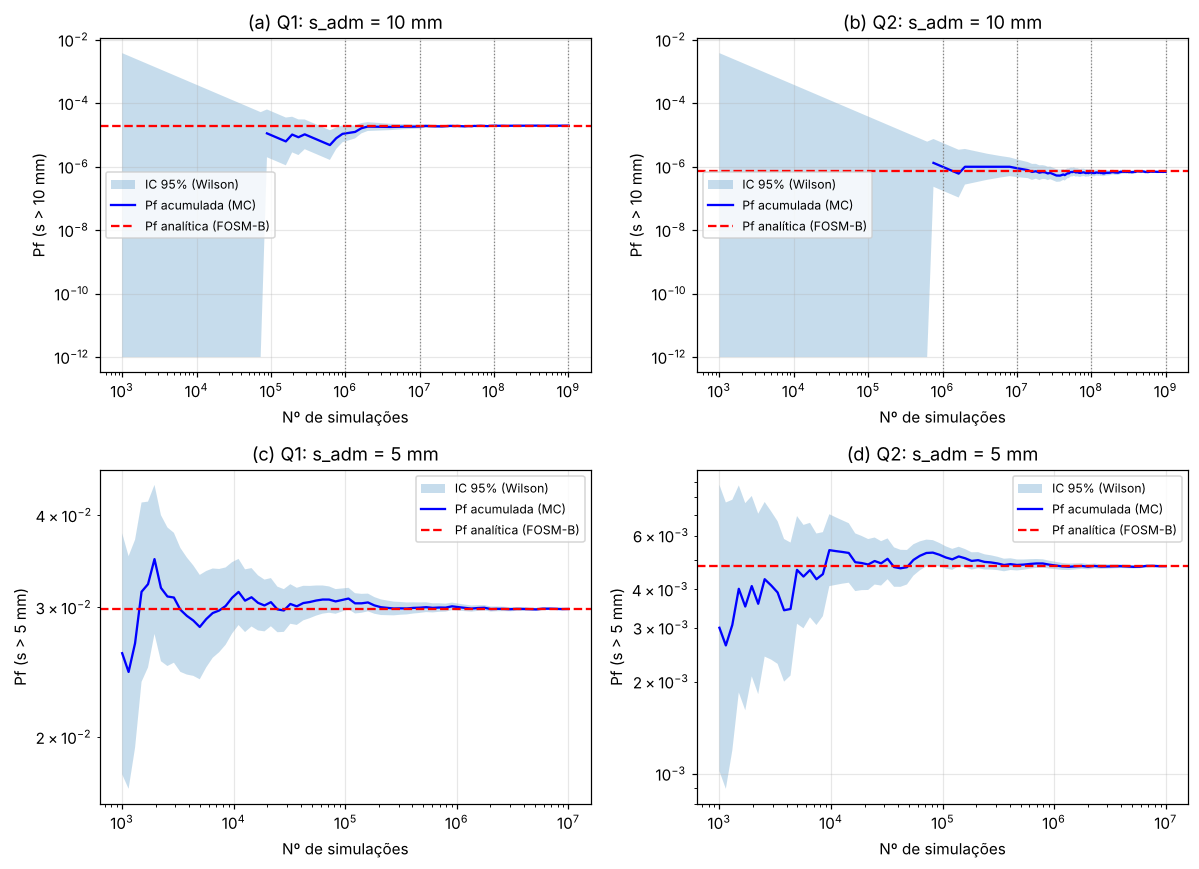

In [ ]:
n_fino = np.unique(np.logspace(3, np.log10(LOTE), 40).astype(int))
n_lote = np.arange(1, n_lotes + 1) * LOTE
letras = iter("abcd")

fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for i, lim in enumerate([S_ADM, 5.0]):
    for ax, (nome, Qm) in zip(axes[i], CARGAS.items()):
        if i == 0:    # estudo em lotes
            ns = np.concatenate([n_fino[n_fino < LOTE], n_lote])
            ks = np.array([exced_ate(nome, int(n)) for n in ns], dtype=float)
        else:         # simulação principal
            ns = np.unique(np.logspace(3, np.log10(N_SIM), 70).astype(int))
            ks = np.cumsum(sim[nome]["s"] > lim)[ns - 1].astype(float)
        p = ks / ns
        lo, hi = wilson(ks, ns)
        ax.fill_between(ns, np.maximum(lo, 1e-12), hi, alpha=0.25, label="IC 95% (Wilson)")
        ax.plot(ns, np.where(p > 0, p, np.nan), "b-", label="Pf acumulada (MC)")
        ax.axhline(fosm(Qm, CV["E"], CV["Q"], CV["D"], lim)["B"]["pf"], color="r", ls="--",
                   label="Pf analítica (FOSM-B)")
        if i == 0:
            for m in MARCOS:
                if m <= N_CONV:
                    ax.axvline(m, color="gray", ls=":", lw=0.8)
        ax.set_xscale("log")
        ax.set_yscale("log")
        ax.set_xlabel("Nº de simulações")
        ax.set_ylabel(f"Pf (s > {lim:g} mm)")
        ax.set_title(f"({next(letras)}) {nome}: s_adm = {lim:g} mm")
        ax.legend(fontsize=8)
fig.tight_layout()
salvar(fig, "fig6_convergencia_pf_1e9.png")
plt.show()